In [1]:
'''Perform comprehensive cross-validation, including stratified k-fold and
 nested cross-validation techniques, to ensure robust model
  generalization and unbiased performance estimation.'''

'Perform comprehensive cross-validation, including stratified k-fold and\n nested cross-validation techniques, to ensure robust model\n  generalization and unbiased performance estimation.'

In [2]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score

In [3]:
# load dataset
df = pd.read_csv('Adm.csv')
print(df.head())

   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0           1        337          118                  4  4.5  4.5  9.65   
1           2        324          107                  4  4.0  4.5  8.87   
2           3        316          104                  3  3.0  3.5  8.00   
3           4        322          110                  3  3.5  2.5  8.67   
4           5        314          103                  2  2.0  3.0  8.21   

   Research  Chance of Admit Application_DateTime  \
0         1             0.92  2022-01-01 09:00:00   
1         1             0.76  2022-01-02 09:00:00   
2         1             0.72  2022-01-04 09:00:00   
3         1             0.80  2022-01-06 09:00:00   
4         0             0.65  2022-01-08 09:00:00   

                              University_Name region  
0    Indian Institute of Technology Kharagpur   East  
1  National Institute of Technology Karnataka  South  
2                          Gujarat University   West  
3   

In [4]:
# prepare features and admission class target
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = (df['Chance of Admit'] >= 0.70).astype(int)
print('Class Distribution:\n', y.value_counts())

Class Distribution:
 Chance of Admit
1    594
0    406
Name: count, dtype: int64


In [5]:
# perform stratified k-fold cross validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = RandomForestClassifier(n_estimators=50, random_state=42)
skf_scores = cross_val_score(model, X, y, cv=skf, scoring='accuracy')

print('Stratified K-Fold Accuracy Scores:', skf_scores)
print('Mean Accuracy:', np.mean(skf_scores))
print('Standard Deviation:', np.std(skf_scores))

Stratified K-Fold Accuracy Scores: [0.705 0.625 0.6   0.71  0.655]
Mean Accuracy: 0.659
Standard Deviation: 0.04328972164382672


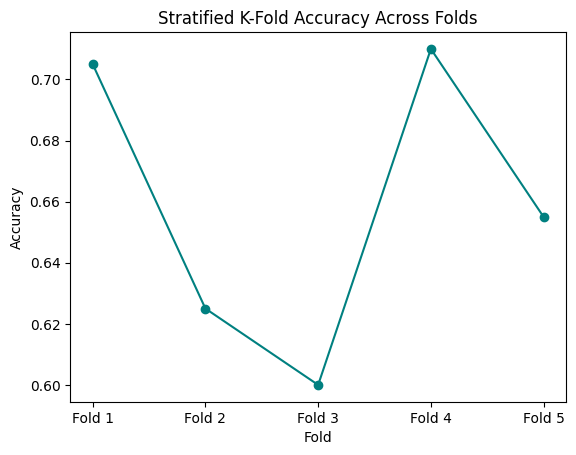

In [6]:
# plot stratified k-fold accuracy across folds
folds = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']
plt.plot(folds, skf_scores, marker='o', color='teal')
plt.title('Stratified K-Fold Accuracy Across Folds')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.show()

In [7]:
# set up nested cross validation
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    'max_depth': [3, 5, 8],
    'n_estimators': [25, 50]
}

grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=inner_cv, scoring='accuracy')

In [8]:
# execute nested cross validation
nested_scores = cross_val_score(grid_search, X, y, cv=outer_cv, scoring='accuracy')

print('Nested CV Scores:', nested_scores)
print('Nested CV Mean Accuracy:', np.mean(nested_scores))
print('Nested CV Standard Deviation:', np.std(nested_scores))

Nested CV Scores: [0.715 0.64  0.62  0.685 0.67 ]
Nested CV Mean Accuracy: 0.666
Nested CV Standard Deviation: 0.03337663853655727


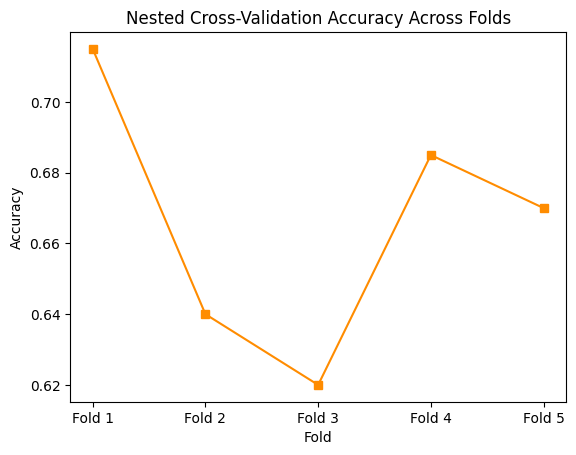

In [9]:
# plot nested cross validation scores
plt.plot(folds, nested_scores, marker='s', color='darkorange')
plt.title('Nested Cross-Validation Accuracy Across Folds')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.show()

In [10]:
# compare stratified k-fold and nested cross validation
cv_comparison = pd.DataFrame({
    'Stratified K-Fold': skf_scores,
    'Nested CV': nested_scores
}, index=folds)
print(cv_comparison)
print('Stratified K-Fold Mean:', np.mean(skf_scores))
print('Nested CV Mean:', np.mean(nested_scores))

        Stratified K-Fold  Nested CV
Fold 1              0.705      0.715
Fold 2              0.625      0.640
Fold 3              0.600      0.620
Fold 4              0.710      0.685
Fold 5              0.655      0.670
Stratified K-Fold Mean: 0.659
Nested CV Mean: 0.666


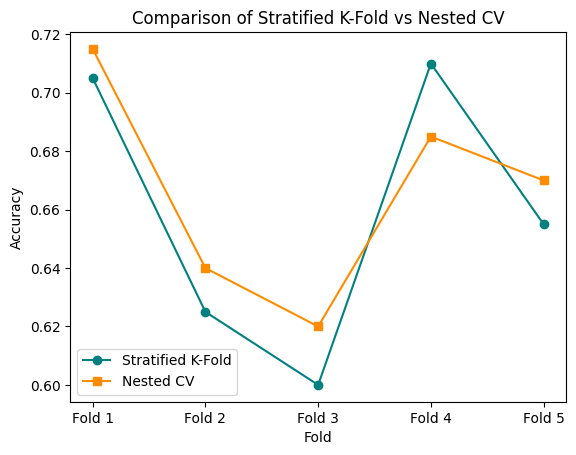

In [11]:
# plot comparison of cross validation methods
plt.plot(folds, skf_scores, marker='o', label='Stratified K-Fold', color='teal')
plt.plot(folds, nested_scores, marker='s', label='Nested CV', color='darkorange')
plt.title('Comparison of Stratified K-Fold vs Nested CV')
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [12]:
# final summary of cross validation
# nested cross validation gives an honest and unbiased estimate of model performance
# stratified k-fold keeps the class balance equal across all folds for reliable evaluation